# 03 · What Features Are Worth & Where Value Remains (Q4, Q6)

**Client:** Residential property investment fund, acquisitions team
**Questions answered here:**
- **Q4:** What does an extra bedroom, bathroom or car space add to a house's price? At what point does adding more stop paying?
- **Q6:** Which suburbs look *undervalued* relative to their characteristics?

**Data:**
- **Domain Sydney sales** (Kaggle `alexlau203/sydney-house-prices`): 11,160 sales from 2016–2021 **with bedrooms,
  bathrooms, parking and land size**, plus suburb fundamentals (distance to CBD, median income, location, elevation, density).
  This is a *separate, smaller sample* from the government data, so it's used where features matter.
- **NSW Valuer General sales** (from notebooks 01–02): 2022–23 house sales, for a *current* view of value.
- **Suburb growth** from Notebook 02.

**Models:**
- **Q4: hedonic regression.** This compares houses **in the same suburb and quarter**, so location and market timing can't
  be mistaken for the value of a bedroom.
- **Q6: gradient-boosted value model** with **suburb-grouped cross-validation**. Each suburb is priced by a model that
  never saw that suburb, so the gap between actual and predicted price is a fair "cheaper or dearer than
  comparable areas" measure.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from matplotlib.ticker import MultipleLocator
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from viz_style import SEGMENT_COLORS, INK_2, MUTED, NEG, POS, apply_style, fig_header, pct_axis, subtitle
from repeat_sales import shrink

apply_style()
FIG = ROOT / "reports" / "figures"
EXPORT = ROOT / "data" / "exports"
pd.options.display.float_format = "{:,.3f}".format
HOUSE = SEGMENT_COLORS["House"]

sales = pd.read_parquet(ROOT / "data/processed/sydney_sales_clean.parquet")
metro_suburbs = set(sales.suburb.unique())
TYPICAL_HOUSE = sales.loc[(sales.dwelling_type == "House") & (sales.year == 2023), "purchase_price"].median()
print(f"Typical Sydney house (2023 median, NSW VG): ${TYPICAL_HOUSE:,.0f}")

Typical Sydney house (2023 median, NSW VG): $1,453,000


## 1 · Preparing the Domain data

In [2]:
raw = pd.read_csv(ROOT / "data/raw/domain/domain_properties.csv")
raw["suburb"] = raw.suburb.str.strip().str.title()
raw["date"] = pd.to_datetime(raw.date_sold, format="%d/%m/%y")
raw["quarter"] = raw.date.dt.to_period("Q").astype(str)

steps = [("Raw Domain sales", raw)]
d = raw[raw.suburb.isin(metro_suburbs)]
steps.append(("Sydney metro suburbs (drops Central Coast / Blue Mountains)", d))
d = d[d.type == "House"]
steps.append(("Houses only (86% of the sample; other types too few to model)", d))
d = d[d.num_bed.between(1, 7) & d.num_bath.between(1, 5) & d.num_parking.between(0, 6)]
steps.append(("Plausible beds 1–7, baths 1–5, parking 0–6 (drops blocks of units / errors)", d))
d = d[d.property_size.between(150, 4000) & d.price.between(300_000, 20_000_000)]
steps.append(("Land 150–4,000 m², price $300k–$20M", d))
houses = d.copy()

pd.DataFrame([(name, len(x)) for name, x in steps], columns=["step", "rows"]).assign(
    removed=lambda t: (-t.rows.diff()).fillna(0).astype(int))

,step,rows,removed
0,Raw Domain sales,11160,0
1,Sydney metro suburbs (drops Central Coast / Bl...,9194,1966
2,Houses only (86% of the sample; other types to...,7724,1470
3,"Plausible beds 1–7, baths 1–5, parking 0–6 (dr...",7548,176
4,"Land 150–4,000 m², price $300k–$20M",7290,258


In [3]:
houses["log_price"] = np.log(houses.price)
houses["log_land"] = np.log(houses.property_size)
houses["bed"] = houses.num_bed.clip(upper=6).map(lambda v: "6+" if v == 6 else str(v))
houses["bath"] = houses.num_bath.clip(upper=4).map(lambda v: "4+" if v == 4 else str(v))
houses["park"] = houses.num_parking.clip(upper=4).map(lambda v: "4+" if v == 4 else str(v))
print(f"{len(houses):,} houses | {houses.suburb.nunique()} suburbs | "
      f"{houses.date.min():%b %Y} to {houses.date.max():%b %Y} | {(houses.date.dt.year == 2021).mean():.0%} sold in 2021")
pd.concat({c: houses[c].value_counts().sort_index() for c in ["bed", "bath", "park"]}, axis=1).fillna(0).astype(int)

7,290 houses | 514 suburbs | Jan 2016 to Jan 2022 | 50% sold in 2021


,bed,bath,park
1,9,1898,1552
2,302,3322,3854
3,2311,1624,832
4,2874,0,0
5,1406,0,0
6+,388,0,0
4+,0,446,735
0,0,0,317


## 2 · Q4 · What is each feature worth?

**Model:** `log(price) ~ bedrooms + bathrooms + parking + log(land) + suburb + quarter`

- **Suburb and quarter fixed effects** mean every comparison is *within the same suburb and the same quarter*.
- Bedrooms, bathrooms and parking are **categories, not straight lines**, so the model can show whether each extra one
  adds less than the one before.
- Standard errors are **clustered by suburb** (sales in one suburb aren't independent).
- Baselines: 3 bedrooms, 2 bathrooms, 2 car spaces.

In [4]:
formula = ("log_price ~ C(bed, Treatment('3')) + C(bath, Treatment('2')) + C(park, Treatment('2'))"
           " + log_land + C(suburb) + C(quarter)")
hedonic = smf.ols(formula, houses).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(houses.suburb)[0]})
print(f"R² = {hedonic.rsquared:.3f} on {int(hedonic.nobs):,} houses")

def level_effects(var, base, levels):
    rows = []
    for lv in levels:
        if lv == base:
            rows.append((lv, 0.0, 0.0, 0.0))
            continue
        key = f"C({var}, Treatment('{base}'))[T.{lv}]"
        b, se = hedonic.params[key], hedonic.bse[key]
        rows.append((lv, np.expm1(b) * 100, np.expm1(b - 1.96 * se) * 100, np.expm1(b + 1.96 * se) * 100))
    out = pd.DataFrame(rows, columns=["level", "effect_%", "ci_low_%", "ci_high_%"])
    out["n"] = out.level.map(houses[var].value_counts())
    return out

effects = {
    "Bedrooms": level_effects("bed", "3", ["2", "3", "4", "5", "6+"]),
    "Bathrooms": level_effects("bath", "2", ["1", "2", "3", "4+"]),
    "Car spaces": level_effects("park", "2", ["0", "1", "2", "3", "4+"]),
}
land_elasticity = hedonic.params["log_land"]
land_ci = hedonic.conf_int().loc["log_land"].to_numpy()
print(f"Land: +10% land -> {((1.1 ** land_elasticity) - 1) * 100:+.1f}% price "
      f"(elasticity {land_elasticity:.3f}, 95% CI {land_ci[0]:.3f}–{land_ci[1]:.3f})")
print("(1-bedroom houses are excluded from the chart: too few sales for a reliable estimate)")
pd.concat(effects, names=["feature"]).round(1)

R² = 0.878 on 7,290 houses
Land: +10% land -> +3.4% price (elasticity 0.355, 95% CI 0.329–0.381)
(1-bedroom houses are excluded from the chart: too few sales for a reliable estimate)


level  effect_%  ci_low_%  ci_high_%     n
feature                                                
Bedrooms   0     2    -6.800    -9.400     -4.100   302
           1     3     0.000     0.000      0.000  2311
           2     4     4.800     3.500      6.100  2874
           3     5    10.200     8.100     12.400  1406
           4    6+     8.800     5.400     12.300   388
Bathrooms  0     1    -6.100    -7.400     -4.800  1898
           1     2     0.000     0.000      0.000  3322
           2     3    10.400     8.600     12.300  1624
           3    4+    30.900    26.500     35.500   446
Car spaces 0     0    -7.000    -9.600     -4.400   317
           1     1    -2.800    -4.100     -1.500  1552
           2     2     0.000     0.000      0.000  3854
           3     3    -0.300    -2.000      1.400   832
           4    4+     3.100     1.000      5.300   735

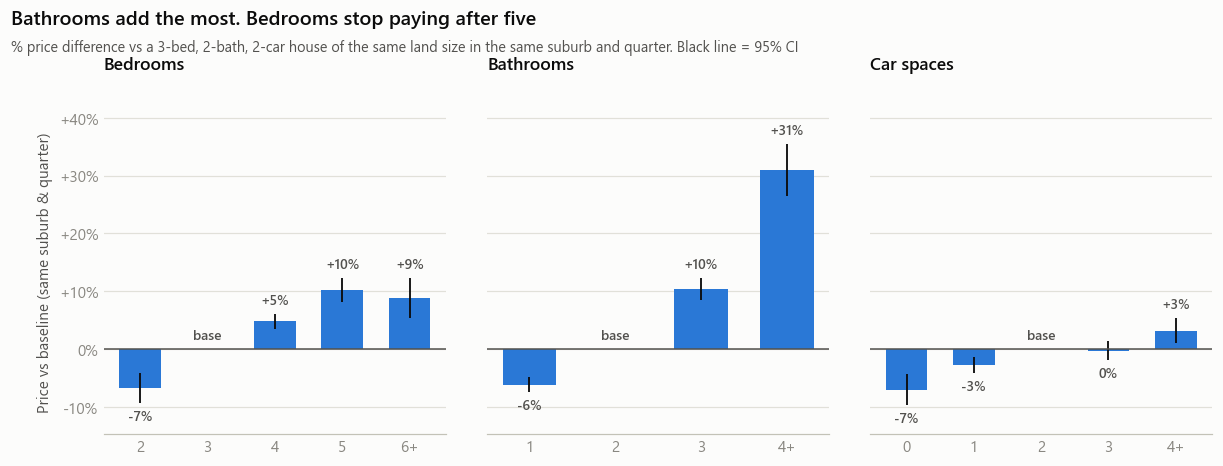

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, (name, e) in zip(axes, effects.items()):
    x = np.arange(len(e))
    base = e["effect_%"] == 0
    ax.bar(x, e["effect_%"], width=0.62, color=np.where(base, "#c3c2b7", HOUSE))
    ax.errorbar(x[~base], e.loc[~base, "effect_%"],
                yerr=[e.loc[~base, "effect_%"] - e.loc[~base, "ci_low_%"], e.loc[~base, "ci_high_%"] - e.loc[~base, "effect_%"]],
                fmt="none", ecolor="#0b0b0b", elinewidth=1.2, capsize=0)
    for xi, (_, r) in zip(x, e.iterrows()):
        label = "base" if r["effect_%"] == 0 else ("0%" if round(r["effect_%"]) == 0 else f"{r['effect_%']:+.0f}%")
        yy = max(r["ci_high_%"], 0) + 1.2 if r["effect_%"] >= 0 else min(r["ci_low_%"], 0) - 1.2
        ax.text(xi, yy, label, ha="center", va="bottom" if r["effect_%"] >= 0 else "top", fontsize=9,
                fontweight="semibold", color=INK_2)
    ax.set_xticks(x, e.level)
    ax.axhline(0, color=INK_2, lw=1)
    ax.set_title(name, fontsize=11.5)
    ax.yaxis.set_major_locator(MultipleLocator(10))
lo = min(e["ci_low_%"].min() for e in effects.values())
axes[0].set_ylim(lo - 5, max(e["ci_high_%"].max() for e in effects.values()) + 6)
pct_axis(axes[0])
axes[0].set_ylabel("Price vs baseline (same suburb & quarter)")
fig_header(fig, "Bathrooms add the most. Bedrooms stop paying after five",
           "% price difference vs a 3-bed, 2-bath, 2-car house of the same land size in the same suburb and quarter. "
           "Black line = 95% CI", top=0.78)
fig.savefig(FIG / "q4_feature_values.png")
plt.show()

In [6]:
# Marginal value of each *additional* feature, in dollars for a typical Sydney house
def steps_of(e):
    e = e.set_index("level")["effect_%"] / 100 + 1
    lv = list(e.index)
    return pd.DataFrame({"step": [f"{a} → {b}" for a, b in zip(lv[:-1], lv[1:])],
                         "marginal_%": [(e[b] / e[a] - 1) * 100 for a, b in zip(lv[:-1], lv[1:])]})

marginal = pd.concat({k: steps_of(v) for k, v in effects.items()}, names=["feature"]).reset_index(level=0)
marginal["marginal_$"] = marginal["marginal_%"] / 100 * TYPICAL_HOUSE
marginal = marginal.reset_index(drop=True)
land_row = pd.DataFrame([{"feature": "Land", "step": "+10% land (e.g. 600 → 660 m²)",
                          "marginal_%": ((1.1 ** land_elasticity) - 1) * 100}])
land_row["marginal_$"] = land_row["marginal_%"] / 100 * TYPICAL_HOUSE
marginal = pd.concat([marginal, land_row], ignore_index=True)
marginal.to_csv(EXPORT / "feature_values.csv", index=False)
pd.options.display.float_format = "{:,.1f}".format
marginal.style.format({"marginal_%": "{:+.1f}%", "marginal_$": "${:,.0f}"}).hide(axis="index")

feature,step,marginal_%,marginal_$
Bedrooms,2 → 3,+7.3%,"$105,842"
Bedrooms,3 → 4,+4.8%,"$69,191"
Bedrooms,4 → 5,+5.2%,"$75,350"
Bedrooms,5 → 6+,-1.3%,"$-18,442"
Bathrooms,1 → 2,+6.5%,"$94,994"
Bathrooms,2 → 3,+10.4%,"$151,247"
Bathrooms,3 → 4+,+18.6%,"$269,841"
Car spaces,0 → 1,+4.6%,"$66,356"
Car spaces,1 → 2,+2.9%,"$41,834"
Car spaces,2 → 3,-0.3%,"$-4,261"


### Finding (Q4): bathrooms carry the biggest premium, and bedrooms stop adding value after the fifth

Value of each **additional** feature for a typical $1.45M Sydney house (same suburb, quarter and land size):

| Feature | Step | Adds | ≈ $ |
|---|---|---:|---:|
| **Bathrooms** | 1 → 2 | +6.5% | $95k |
| | 2 → 3 | **+10.4%** | **$151k** |
| | 3 → 4+ | +18.6% | $270k |
| **Bedrooms** | 2 → 3 | +7.3% | $106k |
| | 3 → 4 | +4.8% | $69k |
| | 4 → 5 | +5.2% | $75k |
| | 5 → 6+ | **−1.3%** (no gain) | — |
| **Car spaces** | 0 → 1 | +4.6% | $66k |
| | 1 → 2 | +2.9% | $42k |
| | 2 → 3 | −0.3% (no gain) | — |
| **Land** | +10% | +3.4% | $50k |

- **Bedrooms stop paying after five.** A 6th bedroom adds nothing on average. **Parking stops paying at two spaces.**
- **Bathrooms are the strongest price signal**, and their premium *grows* with each one added.
- **Land:** doubling the lot size adds about 28% (elasticity 0.36). Land matters, but less than proportionally.
- The model explains **88%** of price variation. All effects shown have 95% confidence intervals that exclude zero,
  except the "no gain" steps.

> **What this means for the fund:** when buying, **target 4–5 bedroom, 3-bathroom houses on 2 car spaces**. That's where
> the features still earn a premium. Don't pay extra for a 6th bedroom or a 3rd garage.
>
> **Important caveat:** there's no floor area in this data. A house with more bathrooms is usually **bigger, newer or
> renovated**, so the bathroom premium partly measures overall size and quality. It says what a 3-bathroom house
> *sells for*, not that *adding* a bathroom returns $151k. Test the value of a specific renovation against build cost
> before relying on it.

## 3 · Q6 · Which suburbs look undervalued?

### 3a · A value model: what explains a house price?
Before labelling anything "cheap", we need a model that prices houses from **features + suburb fundamentals**
(no suburb names). The key design choice is **suburb-grouped cross-validation**: the data is split by *suburb*, so every
prediction for a suburb comes from a model trained only on *other* suburbs. Ordinary random splits would let the model
memorise each suburb's price level and make every suburb look "fairly priced".

In [7]:
houses["t_days"] = (houses.date - pd.Timestamp("2016-01-01")).dt.days
houses["density"] = houses.suburb_population / houses.suburb_sqkm
FEATURES = {"num_bed": "Bedrooms", "num_bath": "Bathrooms", "num_parking": "Car spaces", "log_land": "Land size",
            "km_from_cbd": "Distance to CBD", "suburb_median_income": "Suburb income", "suburb_lat": "North–south position",
            "suburb_lng": "East–west position", "suburb_elevation": "Elevation", "density": "Population density",
            "t_days": "Sale date"}
X, y, groups = houses[list(FEATURES)], houses.log_price.to_numpy(), houses.suburb.to_numpy()

def gbm():
    return HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, min_samples_leaf=30,
                                         l2_regularization=1.0, random_state=0)

cv = GroupKFold(n_splits=5)
oof = {"Linear regression": np.zeros(len(y)), "Gradient boosting": np.zeros(len(y))}
importances = []
for tr, te in cv.split(X, y, groups):
    oof["Linear regression"][te] = LinearRegression().fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
    model = gbm().fit(X.iloc[tr], y[tr])
    oof["Gradient boosting"][te] = model.predict(X.iloc[te])
    pi = permutation_importance(model, X.iloc[te], y[te], n_repeats=5, random_state=0, scoring="r2")
    importances.append(pi.importances_mean)

def scores(pred):
    err = np.expm1(y - pred)
    return {"R² (unseen suburbs)": 1 - np.var(y - pred) / np.var(y),
            "median abs error %": np.median(np.abs(err)) * 100,
            "within ±20% of price": np.mean(np.abs(err) <= 0.20) * 100}

pd.options.display.float_format = "{:,.2f}".format
pd.DataFrame({k: scores(v) for k, v in oof.items()}).T

,R² (unseen suburbs),median abs error %,within ±20% of price
Linear regression,0.76,15.29,62.07
Gradient boosting,0.82,11.88,71.52


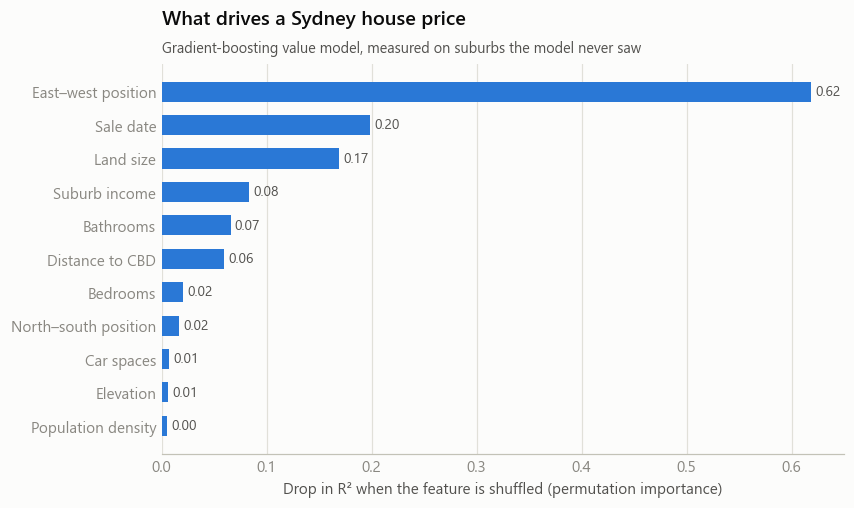

In [8]:
imp = pd.Series(np.mean(importances, axis=0), index=[FEATURES[c] for c in FEATURES]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(imp.index, imp.values, color=HOUSE, height=0.6)
for yi, v in enumerate(imp.values):
    ax.text(v + 0.004, yi, f"{v:.2f}", va="center", fontsize=9, color=INK_2)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Drop in R² when the feature is shuffled (permutation importance)")
ax.set_title("What drives a Sydney house price")
subtitle(ax, "Gradient-boosting value model, measured on suburbs the model never saw")
fig.savefig(FIG / "q6_price_drivers.png")
plt.show()

### Finding: location outweighs every feature of the house itself

- The gradient-boosting model prices **unseen suburbs** with R² = 0.82 and a median error of **11.9%**. **72%** of
  predictions fall within ±20% of the sale price. It clearly beats linear regression (R² 0.76, 15.3% error), because
  location effects aren't straight lines.
- **East–west position** is by far the strongest driver: Sydney's price gradient runs from the coast to the west.
  **Sale date** comes next (the 2021 boom), then **land size**. Bedrooms and parking add little *once location is known*.

> **What this means for the fund:** in Sydney, *where* dominates *what*. A lesser house in a better location has usually
> been the stronger asset, which matches Notebook 02's finding that the premium coastal and northern areas grew fastest.

### 3b · A *current* value gap (2022–23)
The Domain sample ends in 2021. For a current view, the same approach is applied to **2022–23 government sales**
(tens of thousands of houses with land size), with the suburb fundamentals from Domain attached. That sample has no
bedroom or bathroom counts, but it's large and recent.

**Value gap** = a suburb's average (actual − predicted) log price, **shrunk** toward zero for suburbs with fewer sales
(same empirical-Bayes idea as Notebook 02). Negative = cheaper than comparable areas.

In [9]:
fund = raw.groupby("suburb").agg(km_from_cbd=("km_from_cbd", "median"), income=("suburb_median_income", "median"),
                                  lat=("suburb_lat", "median"), lng=("suburb_lng", "median"),
                                  elevation=("suburb_elevation", "median"), pop=("suburb_population", "median"),
                                  sqkm=("suburb_sqkm", "median"))
fund["density"] = fund["pop"] / fund.sqkm

vg = sales[(sales.dwelling_type == "House") & (sales.year >= 2022) & sales.land_sqm.between(150, 4000)]
vg = vg.join(fund, on="suburb", how="inner").copy()
vg["log_price"] = np.log(vg.purchase_price)
vg["log_land"] = np.log(vg.land_sqm)
vg["t_days"] = (vg.contract_date - pd.Timestamp("2022-01-01")).dt.days
VG_FEATURES = ["log_land", "km_from_cbd", "income", "lat", "lng", "elevation", "density", "t_days"]
print(f"{len(vg):,} house sales 2022–23 in {vg.suburb.nunique()} suburbs with fundamentals")

vg["pred"] = 0.0
for tr, te in GroupKFold(n_splits=5).split(vg, groups=vg.suburb):
    m = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, min_samples_leaf=50,
                                      l2_regularization=1.0, random_state=0)
    m.fit(vg[VG_FEATURES].iloc[tr], vg.log_price.iloc[tr])
    vg.iloc[te, vg.columns.get_loc("pred")] = m.predict(vg[VG_FEATURES].iloc[te])
vg["resid"] = vg.log_price - vg.pred
r = vg.resid
print(f"Grouped-CV R² = {1 - r.var() / vg.log_price.var():.2f} | median abs error "
      f"{np.median(np.abs(np.expm1(r))) * 100:.1f}% (lower than the Domain model: no beds/baths here)")

MIN_SALES = 30
gap = vg.groupby("suburb").resid.agg(["mean", "std", "size"]).query("size >= @MIN_SALES")
gap["se"] = gap["std"] / np.sqrt(gap["size"])
gap["gap_shrunk"], tau = shrink(gap["mean"], gap["se"])
gap["value_gap_%"] = np.expm1(gap.gap_shrunk) * 100
gap["median_price_2022_23"] = vg.groupby("suburb").purchase_price.median()
print(f"{len(gap)} suburbs with at least {MIN_SALES} sales | true spread of suburb gaps (tau) = {tau:.2f} log pts")

# Cross-check: does the older, feature-rich Domain model agree on which suburbs are cheap?
houses["resid"] = y - oof["Gradient boosting"]
dom_gap = houses.groupby("suburb").resid.agg(["mean", "size"]).query("size >= 10")["mean"]
both = gap.join(dom_gap.rename("domain_gap"), how="inner")
print(f"Agreement with the Domain feature model (2016–21), {len(both)} suburbs: "
      f"r = {np.corrcoef(both.gap_shrunk, both.domain_gap)[0, 1]:.2f}")

68,048 house sales 2022–23 in 528 suburbs with fundamentals


Grouped-CV R² = 0.66 | median abs error 15.5% (lower than the Domain model: no beds/baths here)
436 suburbs with at least 30 sales | true spread of suburb gaps (tau) = 0.14 log pts
Agreement with the Domain feature model (2016–21), 315 suburbs: r = 0.65


### The trap: the naive "most undervalued" list
Here are the suburbs that are cheapest relative to the model, before any sense check:

In [10]:
gap.nsmallest(10, "value_gap_%")[["size", "value_gap_%", "median_price_2022_23"]].rename(columns={"size": "sales"})

,sales,value_gap_%,median_price_2022_23
suburb,,,
Kurnell,49,-40.49,"1,600,000.00"
Kings Park,106,-33.43,"1,015,000.00"
Carramar,41,-28.92,"840,500.00"
Little Bay,46,-26.91,"2,687,500.00"
Berowra,119,-25.15,"1,480,000.00"
Lalor Park,234,-24.06,"850,000.00"
Lane Cove North,74,-22.96,"2,597,500.00"
Mount Kuring-Gai,38,-22.66,"1,452,500.00"
Wattle Grove,172,-22.54,"1,067,500.00"


**Why this list is a trap.** The names at the top are likely cheap for reasons the model can't see:
- **Kurnell:** next to the former Caltex refinery (now a fuel terminal), near airport flight paths, with one road in and out.
- **Kings Park:** next to a large industrial area.
- **Carramar:** a flood-prone area along Prospect Creek.
- **Berowra / Mount Kuring-gai:** bushland edge (bushfire exposure) at the far north of the rail line.

A value model only measures what it's given. The "gap" here is mostly the price of **flood, industry, noise and access**,
not a market mistake. Presenting this list to an investment committee as "undervalued" would be a serious error, so the
screen below adds an independent demand check.

### 3c · The value screen: proven demand, still priced below comparable areas
The model can't see flood risk, industry, noise, access or schools, so a price gap alone often just *measures*
those problems. Past like-for-like growth (Notebook 02) is independent evidence that buyers **want** a suburb.
The screen keeps suburbs that meet all three conditions:

1. **Above-median real growth**, 2014–2023 (houses, Notebook 02, shrunk estimate).
2. A **value gap of −5% or less** (cheaper than comparable areas in 2022–23).
3. **At least 30 sales** in 2022–23.

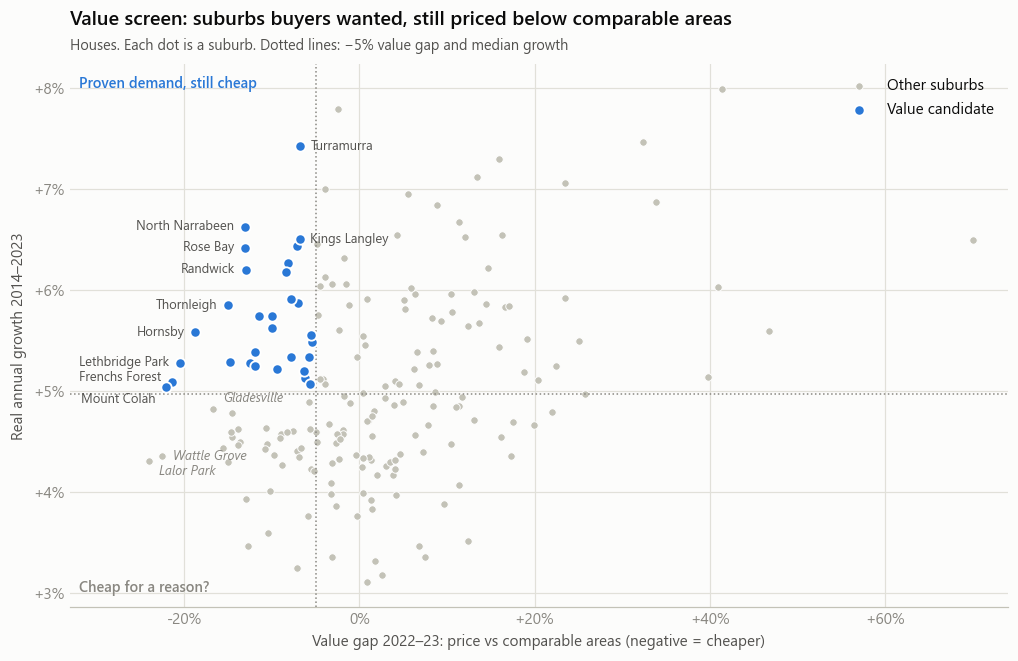

,council,real_cagr_%,value_gap_%,median_price_2022_23,sales_2022_23,on_growth_shortlist
suburb,,,,,,
Mount Colah,Hornsby,5.0,-22.1,"1,562,500.0",164,False
Frenchs Forest,Northern Beaches,5.1,-21.4,"2,120,000.0",299,False
Lethbridge Park,Blacktown,5.3,-20.5,"656,500.0",112,False
Hornsby,Hornsby,5.6,-18.7,"1,650,000.0",202,False
Thornleigh,Hornsby,5.8,-15.0,"1,781,944.0",176,False
Drummoyne,Canada Bay,5.3,-14.8,"2,688,500.0",150,False
North Narrabeen,Northern Beaches,6.6,-13.1,"2,027,500.0",113,False
Rose Bay,Woollahra,6.4,-13.1,"5,325,000.0",112,False
Randwick,Randwick,6.2,-13.0,"3,300,000.0",239,True


In [11]:
growth = pd.read_csv(EXPORT / "suburb_growth.csv").query("segment == 'House'").set_index("suburb")
screen = gap.join(growth[["council", "real_cagr_%", "pairs", "shortlist"]], how="inner")
growth_median = growth["real_cagr_%"].median()
screen["value_candidate"] = (screen["real_cagr_%"] >= growth_median) & (screen["value_gap_%"] <= -5)

fig, ax = plt.subplots(figsize=(11, 6.4))
other = screen[~screen.value_candidate]
cand = screen[screen.value_candidate]
ax.scatter(other["value_gap_%"], other["real_cagr_%"], s=24, color="#c3c2b7", edgecolor="white", linewidth=0.6,
           label="Other suburbs")
ax.scatter(cand["value_gap_%"], cand["real_cagr_%"], s=46, color=HOUSE, edgecolor="white", linewidth=1.2,
           label="Value candidate", zorder=3)
ax.axvline(-5, color=MUTED, ls=":", lw=1)
ax.axhline(growth_median, color=MUTED, ls=":", lw=1)
# Hand-placed labels (dx, dy in points; ha) so none collide
CAND_LABELS = {"Turramurra": (7, 0, "left"), "Kings Langley": (7, 0, "left"),
               "North Narrabeen": (-7, 0, "right"), "Rose Bay": (-7, 0, "right"), "Randwick": (-7, 0, "right"),
               "Thornleigh": (-7, 0, "right"), "Hornsby": (-7, 0, "right"), "Lethbridge Park": (-7, 0, "right"),
               "Frenchs Forest": (-7, 3, "right"), "Mount Colah": (-7, -8, "right")}
for name, (dx, dy, ha) in CAND_LABELS.items():
    if name in cand.index:
        rr = cand.loc[name]
        ax.annotate(name, (rr["value_gap_%"], rr["real_cagr_%"]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8.5, color=INK_2, va="center", ha=ha)
trap = screen[screen["real_cagr_%"] < growth_median].nsmallest(3, "value_gap_%")
for i, (_, rr) in enumerate(trap.sort_values("real_cagr_%").iterrows()):
    ax.annotate(rr.name, (rr["value_gap_%"], rr["real_cagr_%"]), xytext=(7, -7 + 7 * i), textcoords="offset points",
                fontsize=8.5, color=MUTED, va="center", style="italic")
ax.set_xlim(screen["value_gap_%"].min() - 9, screen["value_gap_%"].max() + 4)
ax.text(0.01, 0.98, "Proven demand, still cheap", transform=ax.transAxes, va="top", fontsize=9.5,
        fontweight="semibold", color=HOUSE)
ax.text(0.01, 0.02, "Cheap for a reason?", transform=ax.transAxes, va="bottom", fontsize=9.5,
        fontweight="semibold", color=MUTED)
pct_axis(ax, "x"); pct_axis(ax, "y", decimals=0)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Value gap 2022–23: price vs comparable areas (negative = cheaper)")
ax.set_ylabel("Real annual growth 2014–2023")
ax.set_title("Value screen: suburbs buyers wanted, still priced below comparable areas")
subtitle(ax, "Houses. Each dot is a suburb. Dotted lines: −5% value gap and median growth")
ax.legend(loc="upper right")
fig.savefig(FIG / "q6_value_screen.png")
plt.show()

cols = ["council", "real_cagr_%", "value_gap_%", "median_price_2022_23", "size", "shortlist"]
pd.options.display.float_format = "{:,.1f}".format
(cand.sort_values("value_gap_%")[cols]
     .rename(columns={"size": "sales_2022_23", "shortlist": "on_growth_shortlist"}))

In [12]:
out = screen.reset_index().rename(columns={"index": "suburb", "size": "sales_2022_23"})
out = out[["suburb", "council", "real_cagr_%", "value_gap_%", "median_price_2022_23", "sales_2022_23",
           "shortlist", "value_candidate"]]
out.round(3).to_csv(EXPORT / "suburb_value_gap.csv", index=False)
print("Exported:", *[p.name for p in sorted(EXPORT.glob("*.csv"))], sep="\n  ")

Exported:
  council_risk_return.csv
  feature_values.csv
  suburb_annual_medians.csv
  suburb_growth.csv
  suburb_value_gap.csv
  sydney_index_quarterly.csv


### Finding (Q6): 30 suburbs combine proven demand with a price discount to comparable areas

- **The two value models agree** (r = 0.65 between the 2016–21 feature-rich model and the 2022–23 model), so the gaps
  are stable over time and not just noise.
- **The strongest candidates** (growth above the Sydney median and priced 13–22% below comparable areas):
  **Mount Colah, Frenchs Forest, Hornsby, Thornleigh** (upper north, Hornsby / Northern Beaches councils),
  **Drummoyne, Rose Bay, Randwick, North Narrabeen**, and the affordable **Lethbridge Park** ($657k).
- **Three suburbs are on both lists**, the growth shortlist (Notebook 02) *and* the value screen: **Turramurra,
  Randwick and Kings Langley**. These are the highest-conviction names from this analysis.
- The candidates' median 2022–23 house price is **$1.75M** (range $0.66M–$5.3M), so options exist across budgets.

> **What this means for the fund:** treat this as a **due-diligence list, not a buy list**. For each candidate, check
> what the model can't see (flood and bushfire overlays, school catchments, transport projects, zoning changes) to
> confirm whether the discount is an opportunity or a hidden flaw. Start with Turramurra, Randwick and Kings Langley.

## Summary for the fund

1. **Feature sweet spot:** 4–5 bedrooms, 3 bathrooms, 2 car spaces. A 6th bedroom (−1%) and 3rd car space (0%) add
   nothing. Bathrooms carry the biggest premium, but that partly reflects house size and quality.
2. **Location dominates.** East–west position is the strongest single driver of price, ahead of any house feature.
3. **"Undervalued" needs a demand check.** The model's cheapest suburbs (Kurnell, Kings Park, Carramar) are likely cheap
   because of refineries, industry and floods. Requiring above-median past growth filters these out.
4. **Value screen:** 30 suburbs with proven demand and a 5–22% discount to comparable areas. **Turramurra, Randwick and
   Kings Langley** pass both the growth shortlist and the value screen.

**Limitations:** the Domain sample (7,290 houses) is small and weighted to 2021 (50% of sales). Houses only.
No floor area, condition, school or hazard data. Value gaps are relative to *measured* fundamentals only.

**Exports for the dashboard app** (`data/exports/`): `feature_values.csv`, `suburb_value_gap.csv`.

**Next:** build the Streamlit dashboard from the export tables, and write the executive summary.